In [1]:
import sys
print(sys.executable)

c:\Users\RUDRAKSH\Desktop\Rudraksh\Project\Customer Review Sentiment Analyzer\venv\Scripts\python.exe


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

os.makedirs('../reports/figures', exist_ok=True)

def save(name):
    plt.savefig(f'../reports/figures/{name}.png', dpi=150, bbox_inches='tight')

df = pd.read_csv('../data/processed/clean_reviews.csv')
df['at'] = pd.to_datetime(df['at'])
order = ['positive', 'neutral', 'negative']
colors = {'positive': 'green', 'neutral': 'gold', 'negative': 'red'}

# pandas month-end alias differs by version
FREQ = 'ME' if int(pd.__version__.split('.')[0]) >= 3 or \
       (int(pd.__version__.split('.')[0]) == 2 and int(pd.__version__.split('.')[1]) >= 2) else 'M'

print("Shape:", df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


Shape: (1515, 5)


,content,score,at,sentiment,clean
0,terrible app imo. charging 200 for a 13.5km wh...,1,2026-10-14 10:55:25,negative,terrible app imo charging for a km when under ...
1,good customer care service not like Swiggy,5,2026-10-14 10:54:48,positive,good customer care service not like swiggy
2,"Worst support system, you have to write for th...",1,2026-10-14 10:30:37,negative,worst support system you have to write for the...
3,good food and helpfully app,5,2026-10-14 10:29:07,positive,good food and helpfully app
4,very good app,5,2026-10-14 10:07:11,positive,very good app


In [3]:
print("Columns:", list(df.columns))
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate reviews:", df.duplicated(subset=['content']).sum())
print("\nData types:\n", df.dtypes)
df.describe(include='all').T

Columns: ['content', 'score', 'at', 'sentiment', 'clean']

Missing values:
 content      0
score        0
at           0
sentiment    0
clean        0
dtype: int64

Duplicate reviews: 0

Data types:
 content                 str
score                 int64
at           datetime64[us]
sentiment               str
clean                   str
dtype: object


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
content,1515,1515,terrible app imo. charging 200 for a 13.5km wh...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
score,1515.0,NaN,NaN,NaN,2.671287,1.0,1.0,1.0,5.0,5.0,1.826761
at,1515,NaN,NaN,NaN,2026-10-10 07:22:08.195379,2026-10-06 01:53:36,2026-10-08 12:11:23.500000,2026-10-10 13:24:46,2026-10-11 22:34:02,2026-10-14 10:55:25,NaN
sentiment,1515,3,negative,836,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clean,1515,1493,very nice app,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


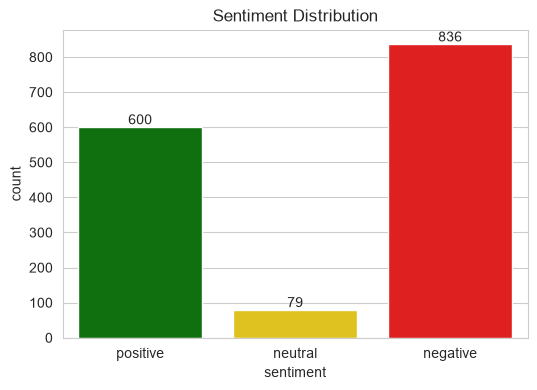

sentiment
negative    55.2
positive    39.6
neutral      5.2
Name: proportion, dtype: float64


In [4]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='sentiment', data=df, order=order, palette=colors, hue='sentiment', legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.title("Sentiment Distribution")
save('01_sentiment_distribution')
plt.show()

print((df['sentiment'].value_counts(normalize=True) * 100).round(1))

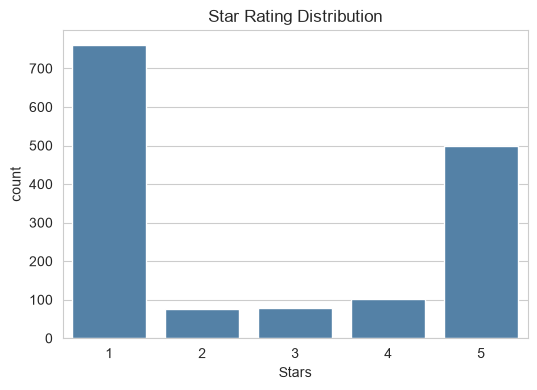

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x='score', data=df, color='steelblue')
plt.title("Star Rating Distribution")
plt.xlabel("Stars")
save('02_star_ratings')
plt.show()

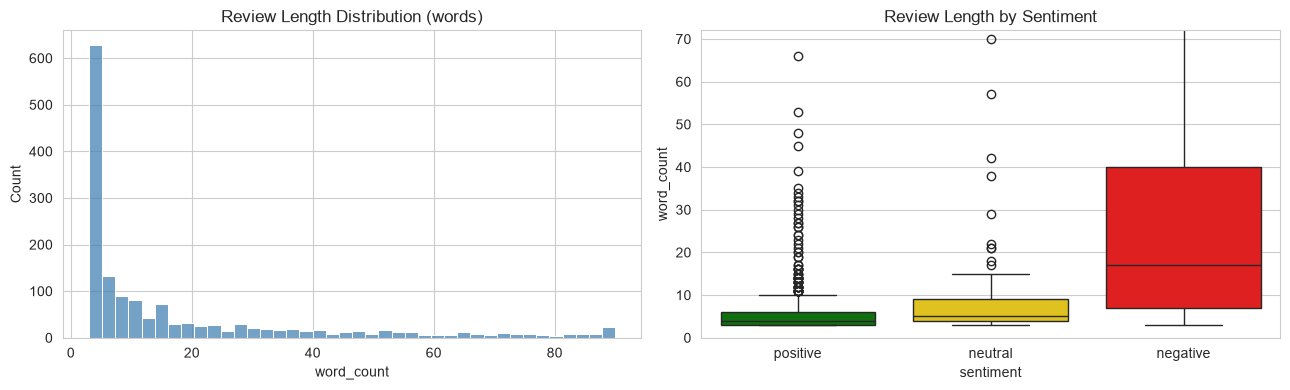

           mean  median
sentiment              
negative   26.8    17.0
neutral    10.1     5.0
positive    6.7     4.0


In [6]:
df['word_count'] = df['clean'].str.split().str.len()
df['char_count'] = df['clean'].str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df['word_count'].clip(upper=df['word_count'].quantile(0.99)),
             bins=40, ax=axes[0], color='steelblue')
axes[0].set_title("Review Length Distribution (words)")

sns.boxplot(x='sentiment', y='word_count', data=df, order=order,
            palette=colors, hue='sentiment', legend=False, ax=axes[1])
axes[1].set_ylim(0, df['word_count'].quantile(0.95))
axes[1].set_title("Review Length by Sentiment")

plt.tight_layout()
save('03_review_length')
plt.show()

print(df.groupby('sentiment')['word_count'].agg(['mean', 'median']).round(1))

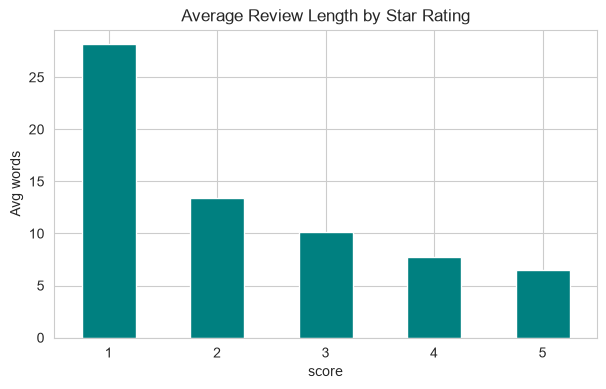

In [7]:
plt.figure(figsize=(7, 4))
df.groupby('score')['word_count'].mean().plot(kind='bar', color='teal')
plt.title("Average Review Length by Star Rating")
plt.ylabel("Avg words")
plt.xticks(rotation=0)
save('04_length_by_rating')
plt.show()

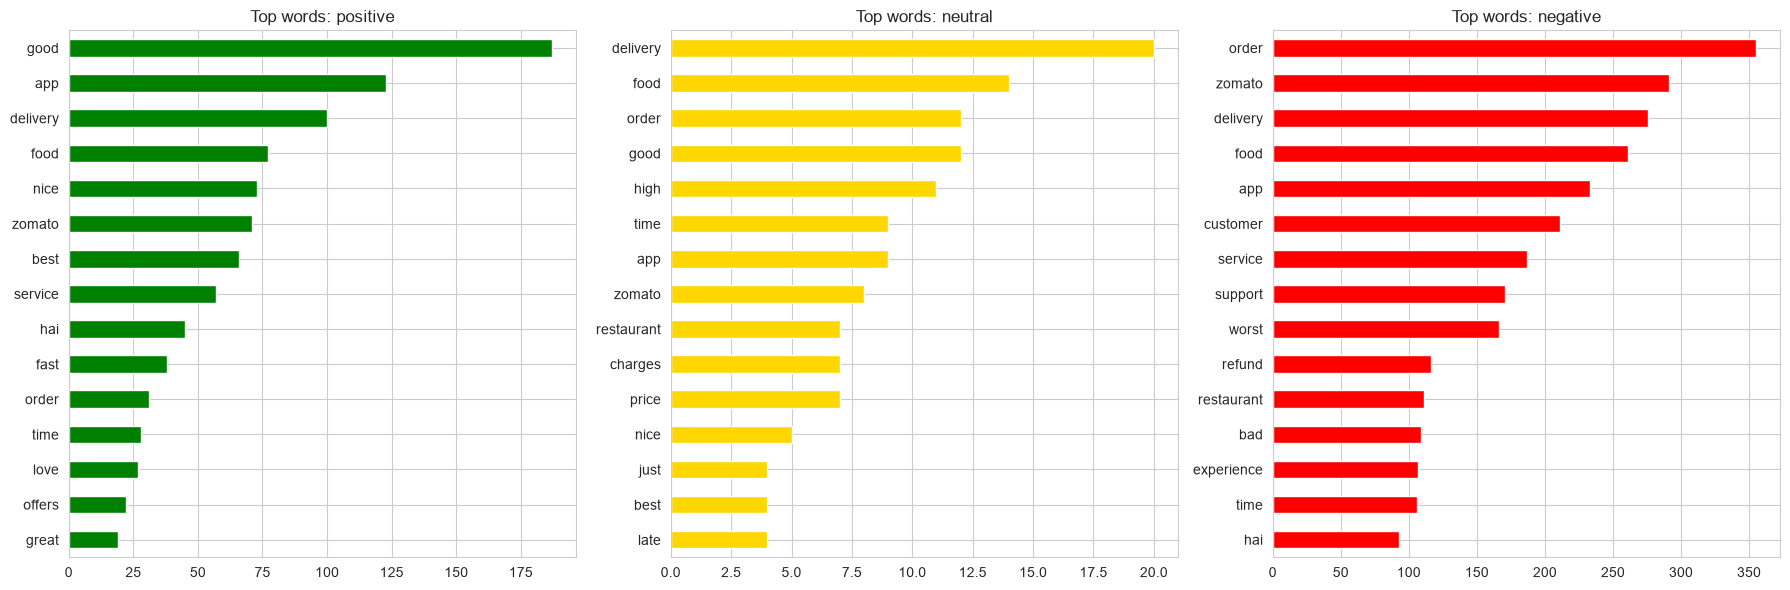

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

def top_ngrams(texts, ngram, n=15):
    vec = CountVectorizer(ngram_range=(ngram, ngram), stop_words='english').fit(texts)
    counts = vec.transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=vec.get_feature_names_out()).nlargest(n)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, s in zip(axes, order):
    top_ngrams(df[df['sentiment'] == s]['clean'], 1).sort_values().plot.barh(ax=ax, color=colors[s])
    ax.set_title(f"Top words: {s}")
plt.tight_layout()
save('05_top_words')
plt.show()

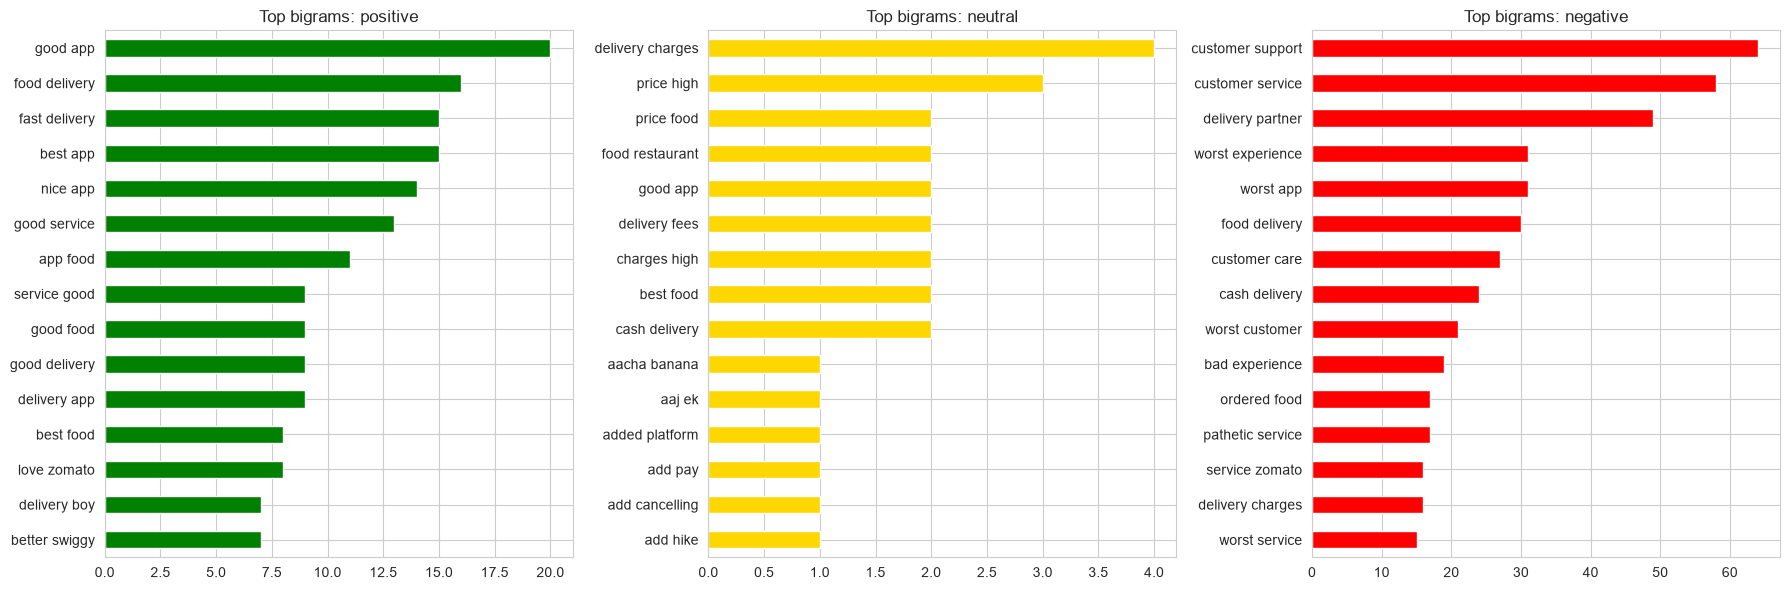

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, s in zip(axes, order):
    top_ngrams(df[df['sentiment'] == s]['clean'], 2).sort_values().plot.barh(ax=ax, color=colors[s])
    ax.set_title(f"Top bigrams: {s}")
plt.tight_layout()
save('06_top_bigrams')
plt.show()

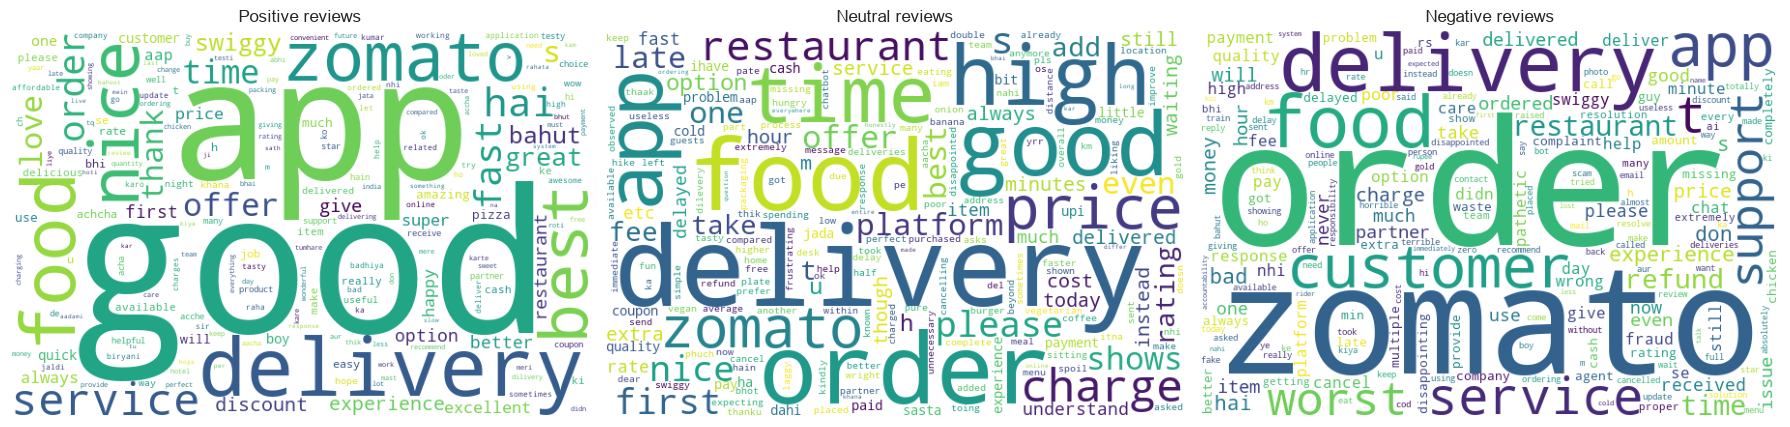

In [10]:
try:
    from wordcloud import WordCloud

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, s in zip(axes, order):
        text = ' '.join(df[df['sentiment'] == s]['clean'])
        wc = WordCloud(width=600, height=400, background_color='white',
                       collocations=False).generate(text)
        ax.imshow(wc)
        ax.set_title(f"{s.capitalize()} reviews")
        ax.axis('off')
    plt.tight_layout()
    save('07_wordclouds')
    plt.show()
except ImportError:
    print("wordcloud not installed - skipping. Use Cells 8 and 9 as your text visuals.")

c:\Users\RUDRAKSH\Desktop\Rudraksh\Project\Customer Review Sentiment Analyzer\venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1615: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


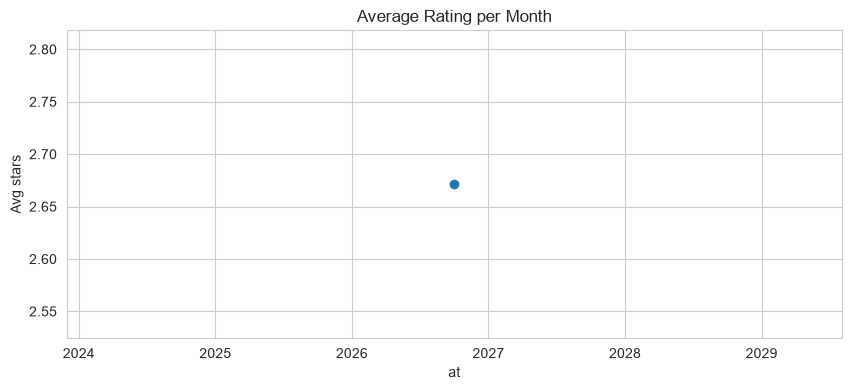

In [11]:
monthly = df.set_index('at')['score'].resample(FREQ).mean()

plt.figure(figsize=(10, 4))
monthly.plot(marker='o')
plt.title("Average Rating per Month")
plt.ylabel("Avg stars")
save('08_rating_trend')
plt.show()

c:\Users\RUDRAKSH\Desktop\Rudraksh\Project\Customer Review Sentiment Analyzer\venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1615: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)
c:\Users\RUDRAKSH\Desktop\Rudraksh\Project\Customer Review Sentiment Analyzer\venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1615: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)
c:\Users\RUDRAKSH\Desktop\Rudraksh\Project\Customer Review Sentiment Analyzer\venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1615: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


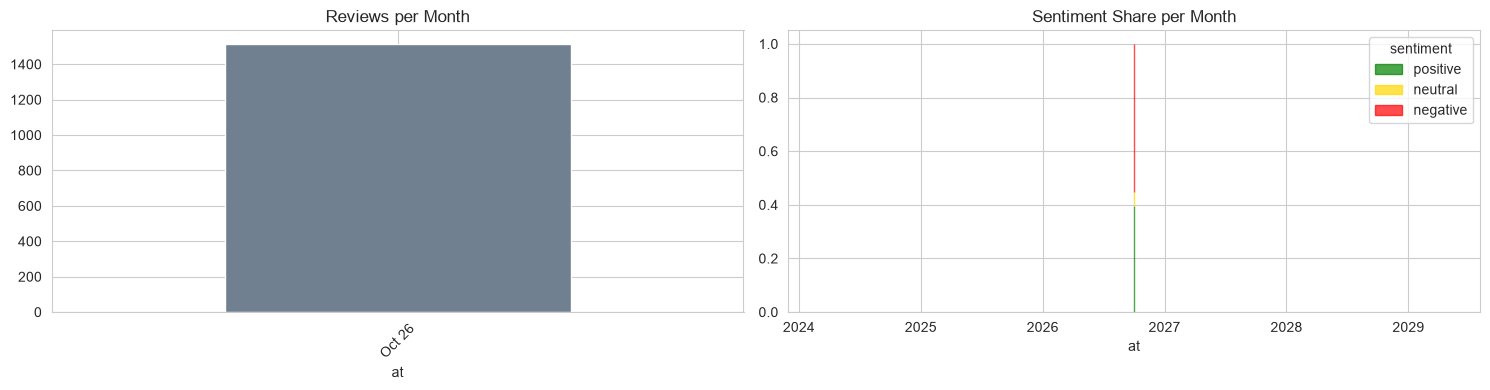

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

df.set_index('at').resample(FREQ).size().plot(kind='bar', ax=axes[0], color='slategray')
axes[0].set_title("Reviews per Month")
axes[0].set_xticklabels([d.strftime('%b %y') for d in
                         df.set_index('at').resample(FREQ).size().index], rotation=45)

share = (df.groupby([pd.Grouper(key='at', freq=FREQ), 'sentiment'])
           .size().unstack(fill_value=0))
share = share.div(share.sum(axis=1), axis=0)
share[order].plot(kind='area', stacked=True, ax=axes[1],
                  color=[colors[s] for s in order], alpha=0.7)
axes[1].set_title("Sentiment Share per Month")

plt.tight_layout()
save('09_time_analysis')
plt.show()

c:\Users\RUDRAKSH\Desktop\Rudraksh\Project\Customer Review Sentiment Analyzer\venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1615: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)
c:\Users\RUDRAKSH\Desktop\Rudraksh\Project\Customer Review Sentiment Analyzer\venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1615: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)
c:\Users\RUDRAKSH\Desktop\Rudraksh\Project\Customer Review Sentiment Analyzer\venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1615: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


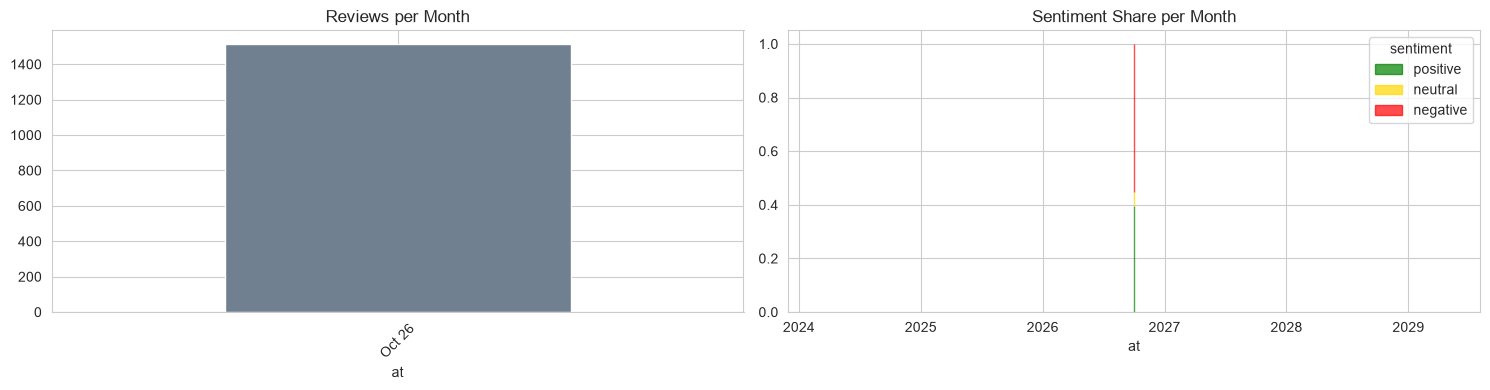

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

df.set_index('at').resample(FREQ).size().plot(kind='bar', ax=axes[0], color='slategray')
axes[0].set_title("Reviews per Month")
axes[0].set_xticklabels([d.strftime('%b %y') for d in
                         df.set_index('at').resample(FREQ).size().index], rotation=45)

share = (df.groupby([pd.Grouper(key='at', freq=FREQ), 'sentiment'])
           .size().unstack(fill_value=0))
share = share.div(share.sum(axis=1), axis=0)
share[order].plot(kind='area', stacked=True, ax=axes[1],
                  color=[colors[s] for s in order], alpha=0.7)
axes[1].set_title("Sentiment Share per Month")

plt.tight_layout()
save('09_time_analysis')
plt.show()

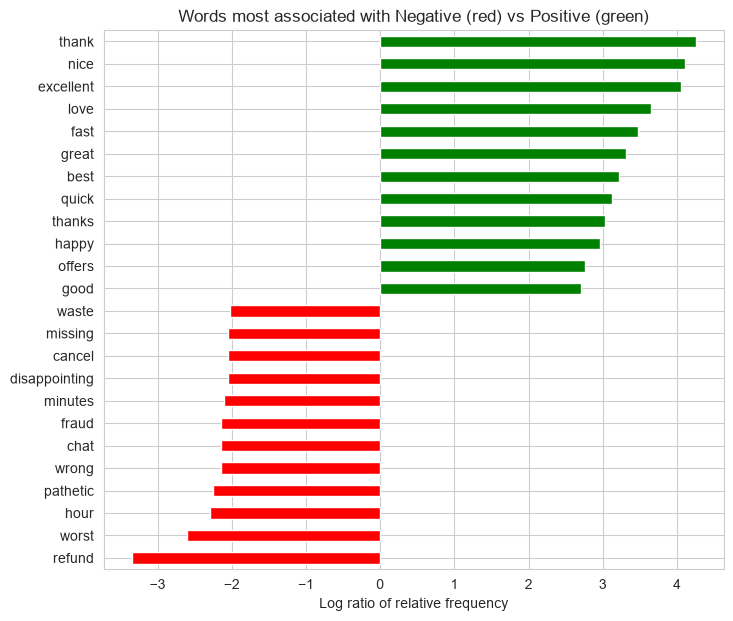

In [14]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

sub = df[df['sentiment'].isin(['positive', 'negative'])]
vec = CountVectorizer(stop_words='english', min_df=10)
X = vec.fit_transform(sub['clean'])
words = np.array(vec.get_feature_names_out())

pos = np.asarray(X[(sub['sentiment'] == 'positive').values].sum(axis=0)).ravel() + 1
neg = np.asarray(X[(sub['sentiment'] == 'negative').values].sum(axis=0)).ravel() + 1
ratio = np.log((pos / pos.sum()) / (neg / neg.sum()))

top = pd.Series(ratio, index=words).sort_values()
combined = pd.concat([top.head(12), top.tail(12)])

plt.figure(figsize=(8, 7))
combined.plot.barh(color=['red']*12 + ['green']*12)
plt.title("Words most associated with Negative (red) vs Positive (green)")
plt.xlabel("Log ratio of relative frequency")
save('10_distinctive_words')
plt.show()

In [15]:
print("=== DATASET SUMMARY ===")
print("Total reviews      :", len(df))
print("Date range         :", df['at'].min().date(), "to", df['at'].max().date())
print("Avg review length  :", round(df['word_count'].mean(), 1), "words")
print("Avg rating         :", round(df['score'].mean(), 2), "stars")

print("\nClass distribution:")
dist = df['sentiment'].value_counts()
for s in order:
    print(f"  {s:9s}: {dist.get(s, 0):6d}  ({dist.get(s, 0)/len(df)*100:.1f}%)")

majority = dist.max() / dist.min()
print(f"\nImbalance ratio (largest : smallest) = {majority:.1f} : 1")
print("\nAvg words by sentiment:")
print(df.groupby('sentiment')['word_count'].mean().round(1).to_string())

=== DATASET SUMMARY ===
Total reviews      : 1515
Date range         : 2026-10-06 to 2026-10-14
Avg review length  : 18.0 words
Avg rating         : 2.67 stars

Class distribution:
  positive :    600  (39.6%)
  neutral  :     79  (5.2%)
  negative :    836  (55.2%)

Imbalance ratio (largest : smallest) = 10.6 : 1

Avg words by sentiment:
sentiment
negative    26.8
neutral     10.1
positive     6.7
